In [1]:
import sys
sys.path.append("..")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.linear_model import LogisticRegression

train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")
X_train = train.drop(columns=["Churn"])
X_test, y_test = test.drop(columns=["Churn"]), test["Churn"]

bundle = joblib.load("../models/churn_model.joblib")
model, threshold, name = bundle["model"], bundle["threshold"], bundle["name"]
print(name, "| threshold:", threshold)

Logistic Regression | threshold: 0.32


In [2]:
pre = model.named_steps["preprocess"]
clf = model.named_steps["model"]

X_bg = pre.transform(X_train)
X_ex = pre.transform(X_test)
names = list(pre.get_feature_names_out())

if isinstance(clf, LogisticRegression):
    explainer = shap.LinearExplainer(clf, X_bg)
    sv = explainer.shap_values(X_ex)
    explanation = shap.Explanation(
        values=sv,
        base_values=np.full(len(sv), explainer.expected_value),
        data=X_ex,
        feature_names=names,
    )
    unit = "log-odds of churn"
else:
    f = lambda d: clf.predict_proba(d)[:, 1]
    explainer = shap.Explainer(f, shap.sample(X_bg, 100, random_state=0))
    explanation = explainer(X_ex[:300])
    explanation.feature_names = names
    unit = "probability of churn"

print("Explained", len(explanation.values), "customers; units:", unit)

Explained 1409 customers; units: log-odds of churn


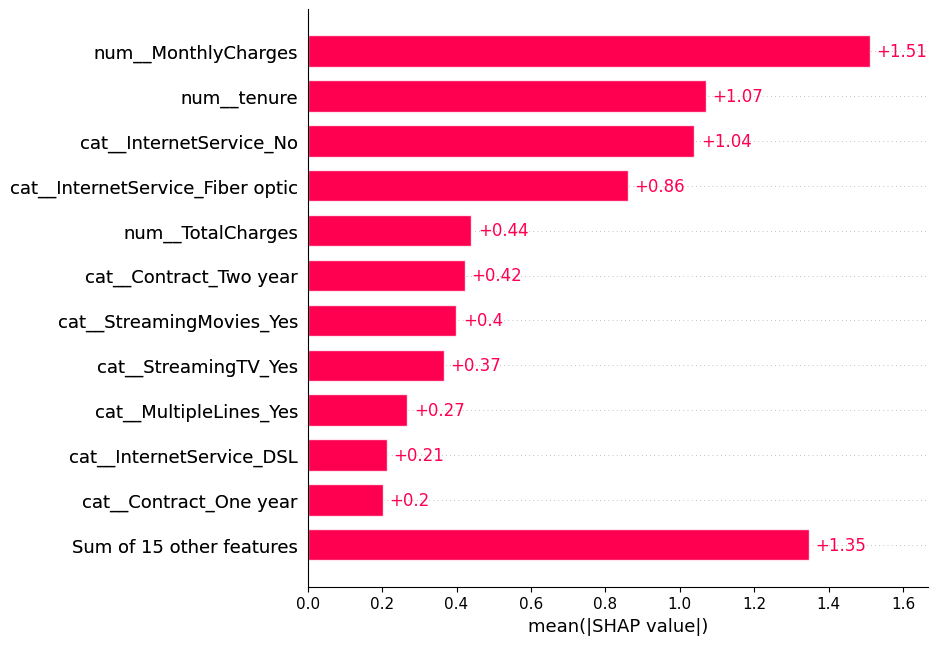

In [3]:
shap.plots.bar(explanation, max_display=12)

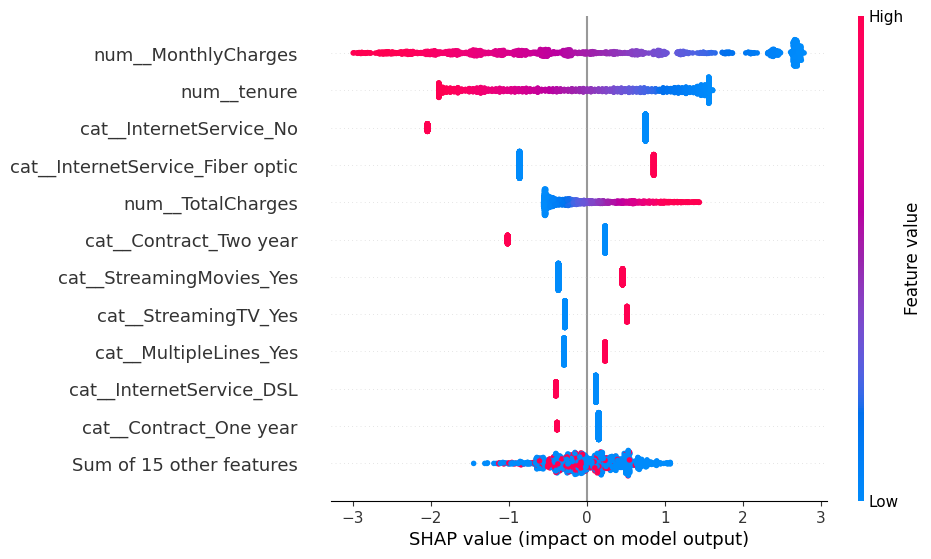

In [4]:
shap.plots.beeswarm(explanation, max_display=12)

Customer index: 1090 | churn probability: 0.937 | actually churned: 1


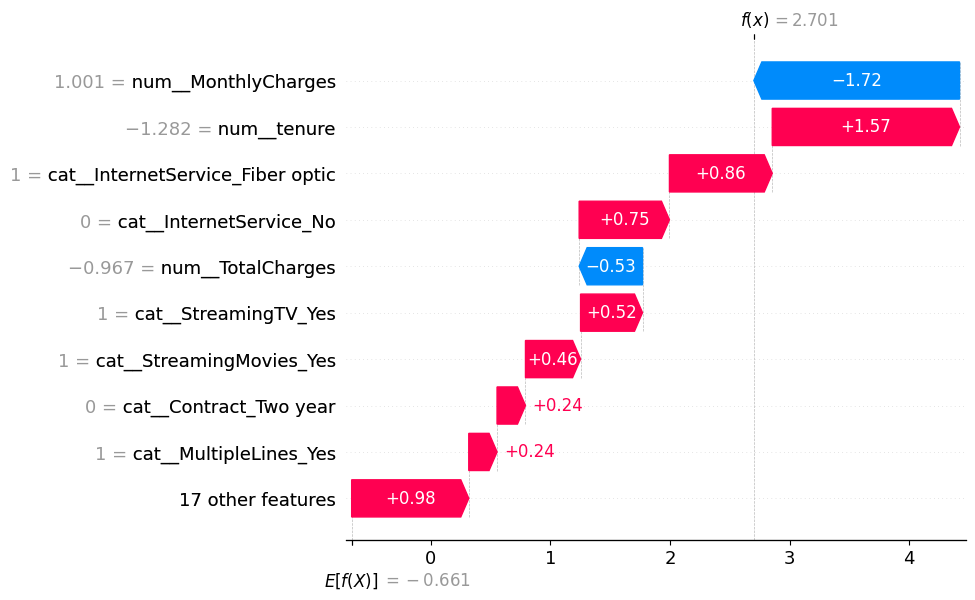

In [5]:
probs = model.predict_proba(X_test)[:, 1]
i = int(np.argsort(probs)[-1])

print("Customer index:", i, "| churn probability:", round(probs[i], 3), "| actually churned:", int(y_test.iloc[i]))
shap.plots.waterfall(explanation[i], max_display=10)

In [6]:
risk = pd.DataFrame({"prob": probs, "churned": y_test.values})
risk["band"] = pd.qcut(risk["prob"], 5, labels=["Lowest", "Low", "Medium", "High", "Highest"])

summary = risk.groupby("band", observed=True).agg(
    customers=("churned", "size"),
    actual_churn_rate=("churned", "mean"),
).round(3)
summary

,customers,actual_churn_rate
band,,
Lowest,282,0.014
Low,282,0.071
Medium,281,0.217
High,282,0.365
Highest,282,0.660


## What drives churn
- Short tenure and month-to-month contracts are the strongest drivers of churn.
- Fiber optic service and high monthly charges push risk up.
- Long contracts, tech support and online security push risk down.
- The highest-risk band churns at about X%, versus about Y% for the lowest band.